# The DSNB in Hyper-Kamiokande: a projection from SK-IV

First-order projection of the SK-IV DSNB analysis (NB01, [arXiv:2109.11174](https://arxiv.org/abs/2109.11174)) to one Hyper-Kamiokande tank. Every expectation of SK-IV per 2-MeV bin (Fig. 24) is scaled to HK by exposure, by the spallation rate at the HK site, and by the neutron-tagging performance. The selection is otherwise kept identical to SK-IV.

This is not a detector simulation. The collaboration has not published the energy resolution, the light yield or the neutron-tagging efficiency for the configuration being built, with 20% coverage and pure water. Neutron tagging is therefore treated as a set of **scenarios**.

The notebook has four parts:
- **0. The detector**
- **1. Scaling method**
- **2. Projected spectra**
- **3. Sensitivity**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from hk_sunu import hk, sk4, stats
from hk_sunu.detector import HYPER_K, SUPER_K
from hk_sunu.plotting import INK, LINESTYLES, MUTED, SERIES, fill, stair, style, use_style

use_style()

window = sk4.spectrum()[:11]
efficiency = sk4.efficiencies()[:11]
edges = np.append(window["erec_lo"], window["erec_hi"][-1])
high = window["erec_lo"] >= 15.5  # the 7 bins of 15.5-29.5 MeV
labels = {"non_ncqe": "Atmospheric non-NCQE", "ncqe": "Atmospheric NCQE", "li9": "Spallation $^9$Li",
          "reactor": "Reactor", "accidental": "Accidental"}
rel_sk = np.array([sk4.BACKGROUND_REL_ERROR[key] for key in sk4.BACKGROUNDS])

# 0. The detector

The Design Report ([arXiv:1805.04163](https://arxiv.org/abs/1805.04163), DR) describes two tanks with 40% photocoverage. Only one tank is being built, with about half the coverage. The values below come from the most recent sources found (November 2026). **[V]** means read in the source; the energy resolution, light yield and tagging efficiency have no official value for the current configuration.

| | SK-IV | HK (one tank) | Source for HK |
|---|---|---|---|
| Water tank | 39.3 m Ø × 41.4 m | 68 m Ø × 71 m, 258 kton | HK SN paper [arXiv:2101.05269](https://arxiv.org/abs/2101.05269) [V] |
| Inner detector | 32.5 kton | 217 kton | same [V] |
| Fiducial volume | 22.5 kton (2 m from wall) | **187 kton** (1.5 m from wall); 188 kton in ICRC2025 | same [V]; [PoS(ICRC2025)1215](https://pos.sissa.it/501/1215) [V] |
| 50-cm PMTs | 11 129 | ≈ 20 000 Box&Line | ICRC2025 [V] |
| Photocoverage | 40% | **20%**, plus ≈ 800 mPMTs | ICRC2025 [V] |
| Single-photon detection efficiency | ≈ 12% | ≈ 24% | EPS-HEP 2025 talk [V] |
| Timing resolution (1 p.e.) | ≈ 3 ns | ≈ 1.5 ns | EPS-HEP 2025 talk [V] |
| Dark rate per PMT | ≈ 4 kHz | ≈ 4 kHz | EPS-HEP 2025 talk [V] |
| Overburden | 1000 m, 2700 m.w.e. | ≈ 600 m, 1620-1750 m.w.e. | ICRC2025 (1620) and DR, [arXiv:2605.11580](https://arxiv.org/abs/2605.11580) (1750) [V] |
| Muon flux | 1.54 × 10⁻⁷ cm⁻² s⁻¹ | 7.55 × 10⁻⁷ cm⁻² s⁻¹ (±20%) | DR Table XXIX, MUSIC simulation [V] |
| Mean muon energy | 258 GeV | 203 GeV | DR Table XXIX [V] |
| Muon rate in the detector | 2 Hz | ≈ 50 Hz | [arXiv:2605.11580](https://arxiv.org/abs/2605.11580) [V] |
| Gadolinium | none in SK-IV | **none**: neutrons tagged only by capture on hydrogen | Project decision (JA, Nov. 2026); [arXiv:2501.08876](https://arxiv.org/abs/2501.08876) |
| Start of data taking | 2008-2018 | mid-2028 | ICRC2025, EPS-HEP 2025 [V] |

Two consequences matter for the DSNB:

- **Light per MeV is about the same as SK-IV.** Half the coverage times twice the detection efficiency gives roughly the same number of hits per MeV. This is an inference, not a published number. It is the basis for keeping the SK-IV energy resolution and cut efficiencies.
- **Spallation is several times worse.** The site is shallower: the muon flux is 4.9 times higher, partly compensated by the lower mean energy.

In [2]:
flux_ratio = hk.MUON_FLUX["HK"] / hk.MUON_FLUX["SK"]
energy_ratio = hk.MUON_MEAN_ENERGY_GEV["HK"] / hk.MUON_MEAN_ENERGY_GEV["SK"]
spall_dr = hk.spallation_scale(flux_ratio, energy_ratio)

print(f"Fiducial mass ratio HK / SK : {HYPER_K.fiducial_kton / SUPER_K.fiducial_kton:.2f}")
print(f"Free protons in HK          : {HYPER_K.free_protons:.3e}")
print(f"Exposure per livetime year  : {hk.FIDUCIAL_KTON:.0f} kton yr (SK-IV total: {hk.sk4_exposure_kton_yr()[1]:.0f})")
print(f"Muon flux ratio             : {flux_ratio:.2f}")
print(f"Mean energy ratio           : {energy_ratio:.2f}")
print(f"f_mu, muon flux (veto loss)  : {hk.MUON_FLUX_RATIO:.2f} x SK")
print(f"f_sp, isotope yield per volume: {spall_dr:.1f} x SK  (flux x <E>^0.75)")

Fiducial mass ratio HK / SK : 8.31
Free protons in HK          : 1.250e+34
Exposure per livetime year  : 187 kton yr (SK-IV total: 183)
Muon flux ratio             : 4.90
Mean energy ratio           : 0.79
f_mu, muon flux (veto loss)  : 4.90 x SK
f_sp, isotope yield per volume: 4.1 x SK  (flux x <E>^0.75)


The factor of about 4 agrees with the DR estimate, 4 ± 1. The collaboration's latest DSNB sensitivity (ICRC2025) uses spallation backgrounds of **6.5 and 13 times SK**, which presumably include effects beyond the isotope yield. All three values are used below as the spallation factor $f_{sp}$.

Two different factors enter, and they are kept separate:
- **$f_{sp}$, isotope production** per unit volume (≈ 4.1 from flux × $\langle E_\mu\rangle^{0.75}$; 6.5 and 13 from ICRC2025). It scales the residual spallation background.
- **$f_\mu = 4.9$, muon flux** per unit area (DR, ±20%). It sets the signal loss of the spallation cut (Sec. 1.2). A lower mean muon energy means fewer isotopes per muon, but not fewer muons to veto, so this factor is the flux ratio, not $f_{sp}$.

One HK livetime year is 187 kton yr, so **one year of HK is about one SK-IV** (183 kton yr). SK-IV had 2970 days of livetime in about ten calendar years, an 81% duty factor. The exposures below are livetime years.

# 1. Scaling method

## 1.1 What scales with what

Each SK-IV expectation in a bin is multiplied by the exposure ratio and then by:

| Component | Tagging | Spallation |
|---|---|---|
| Signal, atmospheric, reactor | $r$ | $\epsilon_{sp}^{f_\mu-1}$ |
| $^9$Li | $r$ | $f_{sp}\,\epsilon_{sp}^{f_\mu-1}$ |
| Accidentals | $k$ | $\epsilon_{sp}^{f_\mu-1}$, times $f_{sp}$ below 15.5 MeV |

$r$ and $k$ are the scenario factors on the tagging efficiency and on the accidental mistag rate (Sec. 1.3).

Accidentals are proportional to the number of events reaching the tagging step. Below 15.5 MeV that sample is dominated by spallation and solar events (Fig. 19), so it is scaled with $f_{sp}$, which is conservative.

## 1.2 The cost of the spallation cut

The spallation cut vetoes regions in time and space around preceding muons. For an event unrelated to the muon, the number of vetoed regions it falls in is Poissonian, so it survives with $\epsilon = e^{-\lambda}$. $\lambda$ is proportional to the muon flux per unit area around the vertex (the vetoes are local, so the detector size does not enter). The same cut in HK therefore keeps

$$\epsilon_{sp}^{HK} = \left(\epsilon_{sp}^{SK}\right)^{f_\mu}.$$

$\epsilon_{sp}^{SK}$ is read from Fig. 18 of the SK paper, normalised to the 97.8% plateau above 23.5 MeV, where there is no spallation cut. With $f_\mu=5$ the rule turns SK efficiencies of 79% and 90% into 31% and 59%. The DR quotes 29% and 54%.

This is the main effect of the depth on the DSNB window. With the same cuts, the residual spallation above 15.5 MeV stays negligible, as in SK-IV, but the signal efficiency drops below 24 MeV. HK could re-optimise the cut using its better timing and the neutron cloud, so the rule is a conservative baseline. Two caveats: SK vetoes more around showering muons, which are rarer at lower $\langle E_\mu\rangle$ (so $f_\mu$ slightly overestimates the loss); and any SK inefficiency not due to random coincidence is also raised to the power $f_\mu$. The figure shows $f_\mu$ = 4.9 ± 20%.

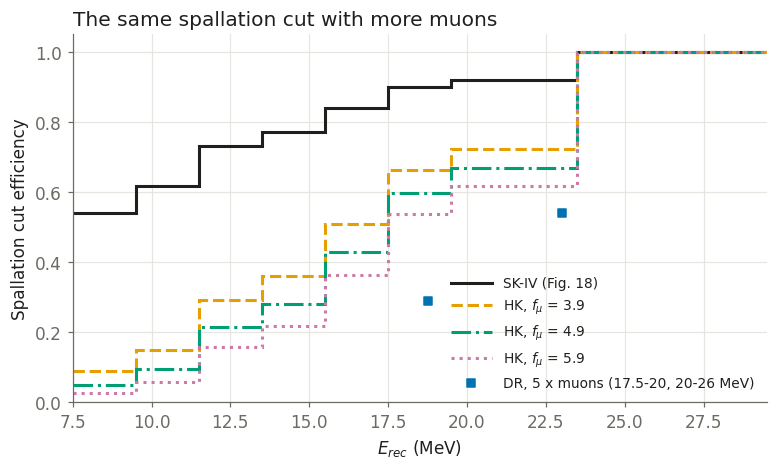

In [3]:
spall_factors = [spall_dr, 6.5, 13.0]  # f_sp: background hypotheses
F_MU = hk.MUON_FLUX_RATIO  # f_mu: veto loss, the same for every f_sp
muon_factors = [0.8 * F_MU, F_MU, 1.2 * F_MU]  # MUSIC uncertainty, +-20%
centres = 0.5 * (edges[:-1] + edges[1:])

fig, ax = plt.subplots()
stair(ax, hk.sk4_spallation_cut_efficiency(), edges, color=INK, label="SK-IV (Fig. 18)")
for i, f in enumerate(muon_factors, start=1):
    stair(ax, hk.spallation_cut_efficiency(f), edges, **style(i), label=f"HK, $f_{{\\mu}}$ = {f:.1f}")
ax.scatter([18.75, 23.0], [0.29, 0.54], marker="s", color=SERIES[0], zorder=3,
           label="DR, 5 x muons (17.5-20, 20-26 MeV)")
ax.set(xlim=(7.5, 29.5), ylim=(0, 1.05), xlabel="$E_{rec}$ (MeV)", ylabel="Spallation cut efficiency")
ax.set_title("The same spallation cut with more muons", loc="left")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()

Below 15.5 MeV the cut keeps less than 40% of the signal even for $f_\mu=3.9$ (−20%), and the $^9$Li and accidental backgrounds grow by $f_{sp}$. This is why the collaboration quotes the HK DSNB window from 16 MeV (DR, ICRC2025). The projections below show the full 7.5-29.5 MeV range, but **the sensitivity uses 15.5-29.5 MeV**.

## 1.3 Neutron tagging scenarios

In SK-IV, tagging exactly one neutron after positron identification has an efficiency of 17-40% depending on the bin (Fig. 18), at the cost of the accidental rate of NB01 Sec. 2.5. For HK, three arguments compete:

- **Similar light per MeV.** The 2.2 MeV γ gives roughly the same number of hits as in SK.
- **More dark noise in the capture window.** There are 20 000 PMTs at about 4 kHz against 11 000 in SK, so 1.8 times more noise hits per 10 ns. The probability that noise mimics a 2.2 MeV γ grows faster than linearly with that number.
- **Larger distances.** The tank radius is about 34 m against 17 m. More light is absorbed, the hit pattern of a weak signal is harder to reconstruct, and the vertex resolution is worse.

The only recent quantitative indication is a trigger study with HK's simulation ([arXiv:2605.31391](https://arxiv.org/abs/2605.31391)). It finds at most 25% efficiency for an isolated 2.2 MeV γ, with no prompt-delayed correlation and 10 kHz of dark noise. The DR quoted 70%, but for 40% coverage.

The scenarios multiply the SK-IV per-bin tagging efficiency by $r$ and the accidental rate by $k$, at the SK-IV working points:

| Scenario | $r$ | $k$ | Meaning |
|---|---|---|---|
| **A**, SK-IV-like | 1 | 1 | Same light yield and noise control as SK-IV |
| **B**, degraded | 0.75 | 3 | More noise and longer distances, partly recovered by better timing |
| **C**, pessimistic | 0.5 | 10 | Tagging close to the trigger-study numbers |
| **D**, DR reference | 67% absolute | 1 | The DR tagging (40% coverage), with SK-IV accidentals. Optimistic and obsolete; an upper reference only |

$r$ and $k$ are treated as independent, but in reality they are tied by the ROC curve of the tagging (NB01, Fig. 15). Scenario D is internally inconsistent for the same reason: a higher efficiency at fixed $k$ requires a better ROC curve.

In [4]:
ntag_sk = efficiency["ntag_one"] / efficiency["cherenkov"]
scenarios = {
    "A": hk.NtagScenario("A, SK-IV-like", 1.0, 1.0),
    "B": hk.NtagScenario("B, degraded", 0.75, 3.0),
    "C": hk.NtagScenario("C, pessimistic", 0.5, 10.0),
    "D": hk.NtagScenario("D, DR reference", np.asarray(0.67 / ntag_sk), 1.0),
}
idx = {key: i for i, key in enumerate(scenarios)}  # style index: A blue/circle, B orange/square, ... as in NB03-04

print("E_rec bin    SK-IV tag eff   D: r")
for lo, hi, e, r in zip(window["erec_lo"], window["erec_hi"], ntag_sk, scenarios["D"].efficiency_scale):
    print(f"{lo:5.1f}-{hi:4.1f}  {e:13.2f}  {r:5.2f}")

E_rec bin    SK-IV tag eff   D: r
  7.5- 9.5           0.17   3.90
  9.5-11.5           0.18   3.77
 11.5-13.5           0.20   3.32
 13.5-15.5           0.24   2.76
 15.5-17.5           0.20   3.42
 17.5-19.5           0.26   2.59
 19.5-21.5           0.40   1.69
 21.5-23.5           0.40   1.69
 23.5-25.5           0.37   1.82
 25.5-27.5           0.30   2.24
 27.5-29.5           0.31   2.19


A check: with $r = k = f_{sp} = f_\mu = 1$ and the SK-IV exposure, the projection gives back Fig. 24 exactly (this is a unit test).

# 2. Projected spectra

Ten livetime years of HK, about 1870 kton yr, with $f_{sp}=6.5$, the lower ICRC2025 value, and $f_\mu = 4.9$. The signal is SK's Horiuchi+09 (6 MeV, max) prediction in Fig. 24, scaled. It therefore does not inherit the 12% discrepancy of the NB01 flux model.

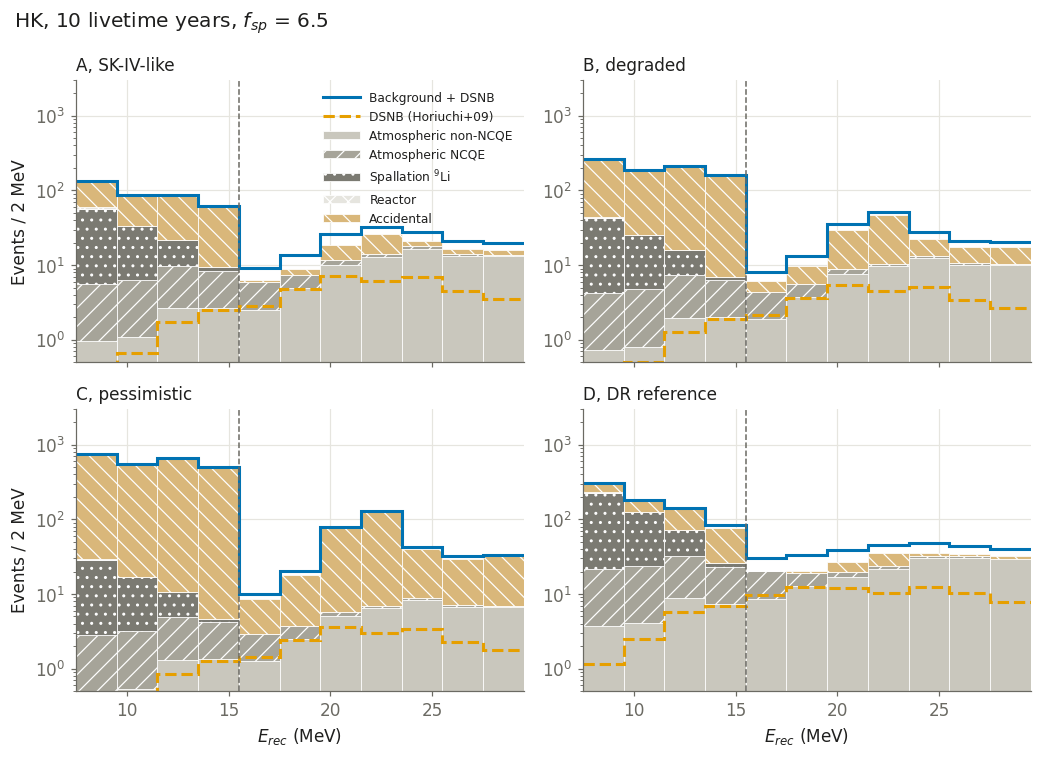

In [5]:
EXPOSURE_10YR = 10 * hk.FIDUCIAL_KTON
F_SP = 6.5  # f_sp; f_mu = F_MU throughout

fig, axes = plt.subplots(2, 2, figsize=(9.6, 7.0), sharex=True)
for ax, (key, scenario) in zip(axes.flat, scenarios.items()):
    out = hk.project(EXPOSURE_10YR, scenario, F_SP, muon_scale=F_MU)
    bottom = np.zeros(11)
    for i, comp in enumerate(sk4.BACKGROUNDS):
        ax.bar(edges[:-1], out[comp], width=2.0, bottom=bottom, align="edge", **fill(i, background=True),
               edgecolor="white", linewidth=0.5, label=labels[comp])
        bottom += out[comp]
    stair(ax, bottom + out["signal"], edges, **style(0), label="Background + DSNB")
    stair(ax, out["signal"], edges, **style(1), label="DSNB (Horiuchi+09)")
    ax.axvline(15.5, color=MUTED, ls="--", lw=1)
    ax.set(yscale="log", ylim=(0.5, 3e3), xlim=(7.5, 29.5))
    ax.set_title(scenario.name, loc="left", fontsize=11)
for ax in axes[1]:
    ax.set_xlabel("$E_{rec}$ (MeV)")
for ax in axes[:, 0]:
    ax.set_ylabel("Events / 2 MeV")
axes[0, 0].legend(loc="upper right", fontsize=8)
fig.suptitle(f"HK, 10 livetime years, $f_{{sp}}$ = {F_SP}", x=0.02, ha="left")
fig.tight_layout()

In [6]:
def summary(scenario, f_sp, exposure=EXPOSURE_10YR):
    out = hk.project(exposure, scenario, f_sp, muon_scale=F_MU)
    return {key: out[key][high].sum() for key in ["signal", *sk4.BACKGROUNDS, "total"]}

sk_ref = {key: window[key][high].sum() for key in sk4.BACKGROUNDS + ["total"]}
sk_ref["signal"] = window["dsnb_horiuchi09"][high].sum()

print(f"Events in 15.5-29.5 MeV, 10 livetime years, f_sp = {F_SP}")
print(f"{'':16} {'DSNB':>6} {'nonNCQE':>8} {'NCQE':>6} {'acc.':>6} {'B total':>8} {'S/B':>6}")
print(f"{'SK-IV (Fig. 24)':16} {sk_ref['signal']:6.1f} {sk_ref['non_ncqe']:8.1f} {sk_ref['ncqe']:6.1f} "
      f"{sk_ref['accidental']:6.1f} {sk_ref['total']:8.1f} {sk_ref['signal'] / sk_ref['total']:6.2f}")
for key, scenario in scenarios.items():
    s = summary(scenario, F_SP)
    print(f"{scenario.name:16} {s['signal']:6.1f} {s['non_ncqe']:8.1f} {s['ncqe']:6.1f} "
          f"{s['accidental']:6.1f} {s['total']:8.1f} {s['signal'] / s['total']:6.2f}")

Events in 15.5-29.5 MeV, 10 livetime years, f_sp = 6.5
                   DSNB  nonNCQE   NCQE   acc.  B total    S/B
SK-IV (Fig. 24)     4.5      8.5    1.6    3.7     13.8   0.33
A, SK-IV-like      35.9     73.6   11.0   28.9    113.5   0.32
B, degraded        26.9     55.2    8.3   86.8    150.2   0.18
C, pessimistic     17.9     36.8    5.5  289.3    331.6   0.05
D, DR reference    75.1    149.3   27.4   28.9    205.7   0.36


Events in 15.5–29.5 MeV, 10 livetime years, $f_{sp} = 6.5$, $f_\mu = 4.9$:

| | DSNB | non-NCQE | NCQE | Accidentals | B total | S/B |
|---|---:|---:|---:|---:|---:|---:|
| SK-IV (Fig. 24) | 4.5 | 8.5 | 1.6 | 3.7 | 13.8 | 0.33 |
| A, SK-IV-like | 35.9 | 73.6 | 11.0 | 28.9 | 113.5 | 0.32 |
| B, degraded | 26.9 | 55.2 | 8.3 | 86.8 | 150.2 | 0.18 |
| C, pessimistic | 17.9 | 36.8 | 5.5 | 289.3 | 331.6 | 0.05 |
| D, DR reference | 75.1 | 149.3 | 27.4 | 28.9 | 205.7 | 0.36 |

B total also includes $^9$Li and reactor events, not shown, so the background columns do not add up to it.

Reading the table:

- **Above 15.5 MeV, HK is limited by atmospheric neutrinos and accidentals**, as in SK-IV. Spallation enters only through the efficiency of its cut.
- **Accidentals decide between the scenarios.** In C they are about 8 times the non-NCQE background, and the signal-to-background ratio drops by a factor of 6 with respect to A.
- **The signal per year after all cuts is 1.8-3.6 events** in A-C, and 7.5 in D. The DR quoted about 70 events in 10 years in 16-30 MeV with 70% tagging, consistent with D. ICRC2025 quotes 4-7 events per year without specifying the cuts.

# 3. Sensitivity

## 3.1 Statistical treatment

The discovery significance uses the median Asimov dataset of a binned shape analysis over the 7 bins of 15.5-29.5 MeV (`stats.binned_significance`). Each background normalisation is a nuisance parameter, Gaussian-constrained with the SK-IV relative uncertainties, fully correlated across bins:

- non-NCQE: 19%
- NCQE: 70%
- $^9$Li: 60%
- reactor: 100%
- accidentals: 20%

The different spectral shapes then let the data constrain the backgrounds, as in a spectral fit, which a single counting bin would miss.

Two systematic hypotheses are shown:
- **SK-IV uncertainties**, as listed above.
- **Halved uncertainties**, an illustration of what better NCQE modelling, SK-Gd measurements and the IWCD could bring. This is not an estimate.

As a reference, the same treatment gives 1.0σ for SK-IV with the Horiuchi+09 signal.

SK-IV, same treatment: 1.03 sigma


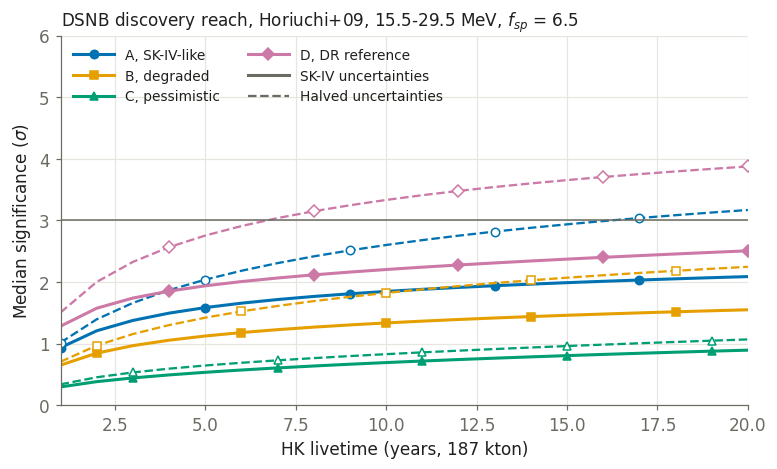

In [7]:
def significance(scenario, f_sp, exposure, rel=rel_sk):
    out = hk.project(exposure, scenario, f_sp, muon_scale=F_MU)
    components = np.array([out[key][high] for key in sk4.BACKGROUNDS])
    return stats.binned_significance(out["signal"][high], components, rel)

sk_out = hk.project(hk.sk4_exposure_kton_yr(), scenarios["A"], 1.0, muon_scale=1.0)
z_sk = stats.binned_significance(sk_out["signal"][high],
                                 np.array([sk_out[key][high] for key in sk4.BACKGROUNDS]), rel_sk)
print(f"SK-IV, same treatment: {z_sk:.2f} sigma")

years = np.arange(1, 21)
fig, ax = plt.subplots()
for key, scenario in scenarios.items():
    z_nom = [significance(scenario, F_SP, y * hk.FIDUCIAL_KTON) for y in years]
    z_half = [significance(scenario, F_SP, y * hk.FIDUCIAL_KTON, rel_sk / 2) for y in years]
    ax.plot(years, z_nom, **style(idx[key], ls="-", marker=True), markevery=(idx[key], 4), label=scenario.name)
    ax.plot(years, z_half, **style(idx[key], ls="--", marker=True), markevery=(idx[key], 4), lw=1.5, mfc="white")
ax.plot([], [], color=MUTED, label="SK-IV uncertainties")
ax.plot([], [], color=MUTED, ls="--", lw=1.5, label="Halved uncertainties")
ax.axhline(3, color=MUTED, lw=1)
ax.set(xlim=(1, 20), ylim=(0, 6), xlabel="HK livetime (years, 187 kton)", ylabel="Median significance ($\\sigma$)")
ax.set_title(f"DSNB discovery reach, Horiuchi+09, 15.5-29.5 MeV, $f_{{sp}}$ = {F_SP}", loc="left", fontsize=11)
ax.legend(loc="upper left", fontsize=9, ncol=2)
fig.tight_layout()

In [8]:
print("Median significance after 10 livetime years (SK-IV uncertainties / halved / statistics only)")
print(f"{'':16}" + "".join(f"{'f_sp = ' + format(f, '.1f'):>22}" for f in spall_factors))
for key, scenario in scenarios.items():
    row = f"{scenario.name:16}"
    for f in spall_factors:
        z = [significance(scenario, f, EXPOSURE_10YR, rel) for rel in (rel_sk, rel_sk / 2, rel_sk * 1e-4)]
        row += f"{z[0]:8.1f}{z[1]:6.1f}{z[2]:6.1f}  "
    print(row)

Median significance after 10 livetime years (SK-IV uncertainties / halved / statistics only)
                            f_sp = 4.1            f_sp = 6.5           f_sp = 13.0
A, SK-IV-like        1.8   2.6   3.3       1.8   2.6   3.3       1.8   2.6   3.3  
B, degraded          1.3   1.8   2.3       1.3   1.8   2.3       1.3   1.8   2.3  


C, pessimistic       0.7   0.8   1.2       0.7   0.8   1.2       0.7   0.8   1.2  
D, DR reference      2.2   3.3   5.1       2.2   3.3   5.1       2.2   3.3   5.1  


**Result.** With the SK-IV uncertainties, ten years of HK reach about 2σ for the Horiuchi+09 flux in scenario A, 1.3σ in B and below 1σ in C. Even the DR tagging (D) stays near 2σ. The statistics-only column shows why: **the measurement is limited by the background systematics, not by statistics**. In A, halving them gains more (1.8 → 2.6σ) than going to the DR tagging (A → D: 1.8 → 2.2σ).

**The table does not depend on $f_{sp}$.** Above 15.5 MeV the residual $^9$Li is negligible, and the accidentals are scaled by $f_{sp}$ only below 15.5 MeV. The spallation level acts on this window only through the cut efficiency, i.e. through $f_\mu$.

The DR quoted 4.2σ in 10 years. It is reached here only with DR-like tagging and close to statistics-only errors, so the DR result must have assumed much smaller background uncertainties than SK-IV's.

## 3.2 Expected differential limits

For comparison with Table V of SK, here is the median 90% C.L. upper limit per bin in the background-only hypothesis. It is computed with the same flat-prior method as in NB01 and converted to flux as

$$\Phi^{HK}_{90} = \Phi^{SK}_{90,\,exp}\;\frac{N^{HK}_{90}}{N^{SK}_{90}}\;\frac{S^{SK}}{S^{HK}}.$$

Here $S$ is the expected DSNB signal in the bin, so $S^{SK}/S^{HK}$ is the inverse of the gain in exposure times efficiency. Using the ratio cancels the flux model.

Below 15.5 MeV, the NB01 limits match SK; in the low-count bins above 15.5 MeV, our limit with a flat prior is weaker than SK's (NB01 Sec. 3). The ratio form cancels part of that bias, but not all of it.

Improvement over SK-IV expected, E_nu 17.3-31.3 MeV:
  A, SK-IV-like    x[2.8 3.4 3.3 3.  3.9 4.1 4.1]
  B, degraded      x[2.2 2.5 1.8 1.5 2.9 3.1 3. ]
  C, pessimistic   x[1.4 1.2 0.5 0.4 1.3 1.5 1.4]


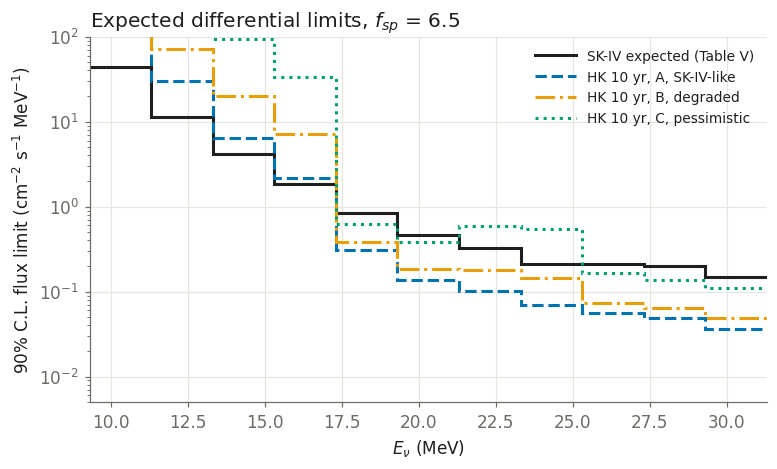

In [9]:
def n90_expected(out):
    components = np.column_stack([out[key] for key in sk4.BACKGROUNDS])
    return np.array([stats.upper_limit(b.sum(), b, rel_sk, n_toys=4000) for b in components])

n90_sk = n90_expected(sk_out)
enu_lo = sk4.TABLE_V["enu_lo"]
enu_edges = np.append(enu_lo, enu_lo[-1] + 2.0)

fig, ax = plt.subplots()
stair(ax, sk4.TABLE_V["expected"], enu_edges, color=INK, label="SK-IV expected (Table V)")
hk_limits = {}
for key in ["A", "B", "C"]:  # line style shifted by one: solid is SK-IV's
    out = hk.project(EXPOSURE_10YR, scenarios[key], F_SP, muon_scale=F_MU)
    hk_limits[key] = sk4.TABLE_V["expected"] * n90_expected(out) / n90_sk * sk_out["signal"] / out["signal"]
    stair(ax, hk_limits[key], enu_edges, **style(idx[key], ls=LINESTYLES[idx[key] + 1]), label=f"HK 10 yr, {scenarios[key].name}")
ax.set(yscale="log", xlim=(9.3, 31.3), ylim=(5e-3, 100), xlabel="$E_\\nu$ (MeV)",
       ylabel="90% C.L. flux limit (cm$^{-2}$ s$^{-1}$ MeV$^{-1}$)")
ax.set_title(f"Expected differential limits, $f_{{sp}}$ = {F_SP}", loc="left")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()

print("Improvement over SK-IV expected, E_nu 17.3-31.3 MeV:")
for key, lim in hk_limits.items():
    print(f"  {scenarios[key].name:16} x{np.round(sk4.TABLE_V['expected'][4:] / lim[4:], 1)}")

In A, ten years improve the SK-IV expected limits by a factor of 2.8-4, close to $\sqrt{10}$. In C the middle bins are **worse than SK-IV**: the accidentals grow by $k$ times the exposure while the signal shrinks, and their 20% uncertainty then dominates the limit.

# 4. Conclusions and open points

- **Spallation closes the window below 15.5 MeV** in HK with SK-IV cuts. Above 15.5 MeV its only effect is the efficiency of its cut, set by the muon flux: in 15.5-23.5 MeV it loses 33-57% of the signal for $f_\mu=4.9$ (27-64% for ±20%). The isotope factor $f_{sp}$ (4.1-13) does not change the sensitivity in this window.
- **Neutron tagging in pure water with 20% coverage is the main unknown** for the signal-to-background ratio, through the accidentals. The scenarios span a factor of 6 in S/B.
- **Background systematics limit the reach after a few years.** With SK-IV uncertainties, ten years give about 1-2σ for Horiuchi+09. Reducing the NCQE and non-NCQE uncertainties matters more than the exposure.

Open points:

1. **Couple $r$ and $k$ through a ROC curve** instead of fixing them independently, and optimise the working point per bin for HK.
2. **Use a DSNB model** (e.g. Kresse+21) and a proper spectral fit with the $\neq 1$ neutron sidebands, as in the SK analysis, instead of scaling Fig. 24.
3. **No Gd in HK.** Neutrons are tagged only by capture on hydrogen, so a Gd scenario is not considered. SK-Gd-like tagging appears in NB03 only as a labelled non-HK reference.
4. **Overburden.** The sources give 1620 or 1750 m.w.e., and the muon flux is a MUSIC simulation with ±20% uncertainty. The 6.5 and 13 factors of ICRC2025 should be understood; in this model they only matter below 15.5 MeV, while the ±20% on $f_\mu$ matters above it.
5. **ICRC2025 and the Neutrino 2026 poster** on HK DSNB sensitivity: worth reading in full to compare assumptions.